### Задача 5. PageRank

Везде считаем, что вершины графа занумерованы подряд с нуля. Основная реализация должна выполняться с использованием библиотеки `python-graphblas`. Допускается использование networkx только для загрузки данных, сравнения производительности.

**Задание 1: Масштабирование на большой граф**

- Загрузите граф `web-Stanford` (~280K узлов) из коллекции SNAP или аналогичный крупный разреженный граф (например, из SuiteSparse Matrix Collection).

- Реализуйте оптимизированную версию PageRank, способную работать с ограниченными ресурсами памяти. Возможные подходы:

    - Использование dtype=dtypes.FP32.
    - Блочная обработка графа (например, через gb.Matrix.ss.split()).

- Проведите бенчмаркинг:

    - Измерьте время выполнения и пиковое потребление памяти.
    - Сравните результаты с базовой последовательной реализацией по критериям: число итераций до сходимости и максимальная разница в рангах.

In [21]:
import os

import graphblas as gb
from graphblas import Matrix, Vector, dtypes, unary, binary, monoid, semiring
from graphblas.io import mmread
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import time
import warnings
import urllib.request
import gzip
from pathlib import Path
import tracemalloc
import random

warnings.filterwarnings('ignore')
plt.style.use('classic')

Тестовый граф (матрица смежности):
"M_84"     nvals  nrows  ncols  dtype         format
gb.Matrix      7      5      5  UINT8  bitmapr (iso)
----------------------------------------------------
   0  1  2  3  4
0     1  1      
1           1   
2           1  1
3              1
4  1            
Iter   0: rdiff=3.40e-01, time=0.32ms
Iter  10: rdiff=3.22e-02, time=0.09ms
Iter  20: rdiff=3.13e-03, time=0.09ms
Iter  30: rdiff=3.48e-04, time=0.08ms
Iter  40: rdiff=3.60e-05, time=0.08ms
Iter  50: rdiff=3.44e-06, time=0.08ms
✓ Сходимость достигнута на итерации 57

Результаты PageRank:
  Node 0: 0.254192
  Node 1: 0.138032
  Node 2: 0.138032
  Node 3: 0.205990
  Node 4: 0.263755


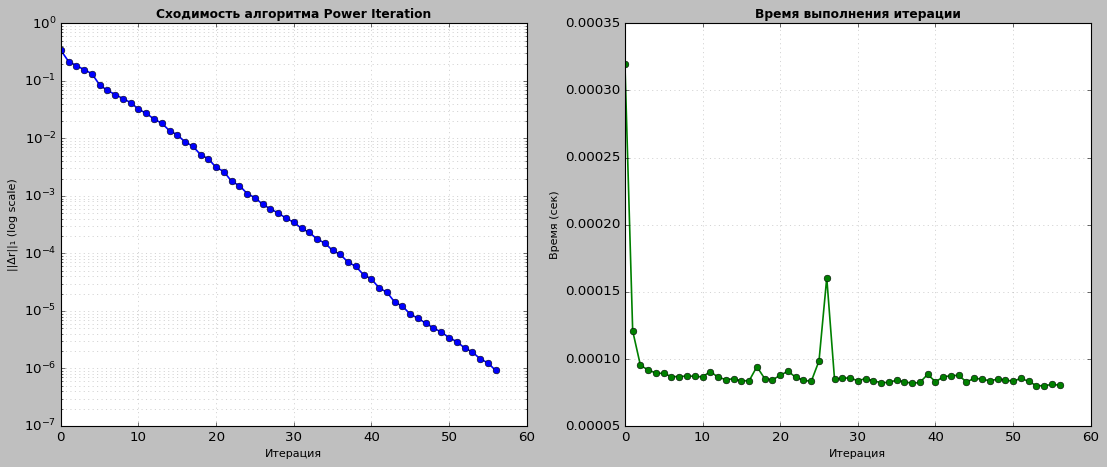

In [22]:
def create_stochastic_matrix(A):
    """
    Преобразует бинарную матрицу смежности в стохастическую матрицу M.
    Гарантирует, что каждая строка i суммируется в 1 (если d_out[i] > 0).
    """
    n = A.nrows
    d_out = A.reduce_rowwise(monoid.plus).new()

    inv_d = Vector(dtypes.FP64, n)
    mask = (d_out > 0).new()
    inv_d(mask=mask.S) << binary.truediv(1.0, d_out)

    # Создаём диагональную матрицу D[i,i] = 1/d_out[i]
    D = Matrix.diag(inv_d)
    # Умножение D @ A масштабирует СТРОКИ: M[i,j] = D[i,i] * A[i,j]
    M = D @ A

    return M, d_out


def pagerank_basic(A, damping=0.85, max_iter=100, tol=1e-6, verbose=False):
    n = A.nrows
    teleport = (1 - damping) / n
    M, d_out = create_stochastic_matrix(A)

    r = Vector(dtypes.FP64, n)
    r[:] << 1.0 / n
    t = Vector(dtypes.FP64, n)
    w = Vector(dtypes.FP64, n)

    history = {'rdiff': [], 'time_per_iter': []}

    for iteration in range(max_iter):
        start_time = time.time()
        t << r
        w << M.T.mxv(t, semiring.plus_times)
        r << binary.times(damping, w)
        r(binary.plus)[:] << teleport

        diff = t.ewise_mult(r, binary.minus).apply(unary.abs)
        rdiff = diff.reduce(monoid.plus).new().value

        iter_time = time.time() - start_time
        history['rdiff'].append(rdiff)
        history['time_per_iter'].append(iter_time)

        if verbose and iteration % 10 == 0:
            print(f"Iter {iteration:3d}: rdiff={rdiff:.2e}, time={iter_time*1000:.2f}ms")

        if rdiff < tol:
            if verbose: print(f"✓ Сходимость достигнута на итерации {iteration+1}")
            break

    return r, history

# Создаём небольшой тестовый граф для проверки
A_test = Matrix.from_coo(
    [0, 0, 1, 2, 2, 3, 4],          # rows
    [1, 2, 3, 3, 4, 4, 0],          # columns
    [1]*7,                          # values
    dtype=dtypes.UINT8
)

print("Тестовый граф (матрица смежности):")
print(A_test)

# Запускаем базовый PageRank на тестовом графе
r_test, hist_test = pagerank_basic(A_test, verbose=True)

print("\n" + "="*50)
print("Результаты PageRank:")
print("="*50)
for i in range(A_test.nrows):
    print(f"  Node {i}: {r_test[i].value:.6f}")

# Визуализация сходимости
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.semilogy(hist_test['rdiff'], 'b-o', linewidth=1.5)
plt.xlabel('Итерация', fontsize=10)
plt.ylabel('||Δr||₁ (log scale)', fontsize=10)
plt.title('Сходимость алгоритма Power Iteration', fontsize=11, fontweight='bold')
plt.grid(True, alpha=0.3, which='both')

plt.subplot(1, 2, 2)
plt.plot(hist_test['time_per_iter'], 'g-o', linewidth=1.5)
plt.xlabel('Итерация', fontsize=10)
plt.ylabel('Время (сек)', fontsize=10)
plt.title('Время выполнения итерации', fontsize=11, fontweight='bold')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
def create_stochastic_matrix_fp32(A):
    """Оптимизированное создание стохастической матрицы в FP32."""
    n = A.nrows
    
    # степени исхода (d_out) в FP32
    d_out = A.reduce_rowwise(monoid.plus[dtypes.FP32]).new()
    
    inv_d = Vector(dtypes.FP32, n)
    mask = (d_out > 0).new()
    
    # 1.0 / d_out
    inv_d(mask=mask.S) << binary.truediv(1.0, d_out)
    
    D = Matrix.diag(inv_d)
    
    M = D.mxm(A, semiring.any_times[dtypes.FP32]).new() 
    return M

def pagerank_optimized(A, damping=0.85, max_iter=100, tol=1e-6, verbose=False):
    """Оптимизированная версия с использованием FP32 и inplace операций."""
    n = A.nrows
    dtype = dtypes.FP32
    teleport = (1.0 - damping) / n
    
    M = create_stochastic_matrix_fp32(A)

    # инициализация векторов в FP32
    r = Vector(dtype, n)
    r[:] << 1.0 / n
    t = Vector(dtype, n)
    w = Vector(dtype, n)

    history = {'rdiff': [], 'time_per_iter': []}

    M_T = M.T.new()

    for iteration in range(max_iter):
        start_time = time.time()
        
        t << r

        w(accum=binary.any) << M_T.mxv(t, semiring.plus_times[dtype])
        
        r << binary.times(damping, w)
        r(binary.plus)[:] << teleport

        diff = t.ewise_mult(r, binary.minus).apply(unary.abs)
        rdiff_val = diff.reduce(monoid.plus[dtype]).new().value
        rdiff = float(rdiff_val) if rdiff_val is not None else 0.0
        
        iter_time = time.time() - start_time
        history['rdiff'].append(rdiff)
        history['time_per_iter'].append(iter_time)

        if rdiff < tol:
            break

    return r, history


Базовый алгоритм (FP64)
  Время выполнения: 0.6358 сек
  Пиковое потребление памяти: 342.95 MB
  Итераций до сходимости: 63

Оптимизированный алгоритм (FP32)
  Время выполнения: 0.4305 сек
  Пиковое потребление памяти: 216.26 MB
  Итераций до сходимости: 63

Максимальная разница в рангах между двумя реализациями: 1.8366e-07


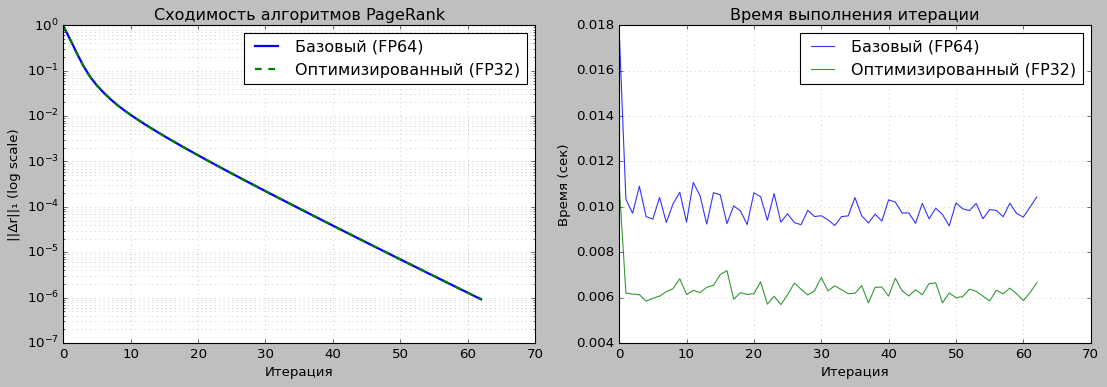

In [24]:
def run_benchmark(func, A, name):
    print(f"\n{name}")
    tracemalloc.start()
    start_time = time.time()
    
    r, history = func(A)
    
    total_time = time.time() - start_time
    current, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    
    iterations = len(history['rdiff'])
    print(f"  Время выполнения: {total_time:.4f} сек")
    print(f"  Пиковое потребление памяти: {peak / 10**6:.2f} MB")
    print(f"  Итераций до сходимости: {iterations}")
    
    return r, history, total_time, peak


filepath = os.path.join('./data', 'web-Stanford.mtx')
A_test = mmread(filepath)

r_basic, hist_basic, time_b, mem_b = run_benchmark(pagerank_basic, A_test, "Базовый алгоритм (FP64)")
r_opt, hist_opt, time_o, mem_o = run_benchmark(pagerank_optimized, A_test, "Оптимизированный алгоритм (FP32)")

diff_vector = r_basic.ewise_mult(r_opt.dup(dtype=dtypes.FP64), binary.minus).apply(unary.abs)
max_diff = diff_vector.reduce(monoid.max).value
print(f"\nМаксимальная разница в рангах между двумя реализациями: {max_diff:.4e}")


plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.semilogy(hist_basic['rdiff'], label='Базовый (FP64)', linewidth=2)
plt.semilogy(hist_opt['rdiff'], label='Оптимизированный (FP32)', linestyle='--', linewidth=2)
plt.xlabel('Итерация')
plt.ylabel('||Δr||₁ (log scale)')
plt.title('Сходимость алгоритмов PageRank')
plt.grid(True, alpha=0.3, which='both')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist_basic['time_per_iter'], label='Базовый (FP64)', alpha=0.8)
plt.plot(hist_opt['time_per_iter'], label='Оптимизированный (FP32)', alpha=0.8)
plt.xlabel('Итерация')
plt.ylabel('Время (сек)')
plt.title('Время выполнения итерации')
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

**Задание 2: Динамический (инкрементальный) PageRank**

Реализуйте функцию быстрого обновления рангов при добавлении новых рёбер без полного пересчёта:

In [25]:
def incremental_pagerank(A_old, r_old, new_edges, damping=0.85, max_iter=50, tol=1e-8):
    """
    Parameters:
    -----------
    A_old : gb.Matrix - исходная матрица смежности (бинарная)
    r_old : gb.Vector - исходный вектор рангов (стационарное решение)
    new_edges : list of tuple - новые рёбра [(src, dst), ...]
    damping : float - коэффициент демпфирования β  
    max_iter : int - число итераций для уточнения обновления

    Returns:
    --------
    r_new : gb.Vector - обновлённый вектор рангов (приближённый)
    """
    n = A_old.nrows
    dtype = r_old.dtype

    # обновление матрицы A
    A_new = A_old.dup()
    rows, cols = zip(*new_edges)
    # новые ребра (единицы)
    A_new[list(rows), list(cols)] = 1

    changed_nodes = sorted(list(set(rows)))
    
    # новые степени исхода
    d_out_new = A_new.reduce_rowwise(monoid.plus).new()
    
    inv_d_new = Vector(dtype, n)
    mask = (d_out_new > 0)
    inv_d_new(mask=mask.S) << binary.truediv(1.0, d_out_new)
    M_new = Matrix.diag(inv_d_new) @ A_new

    # ΔM = M_new - M_old 
    M_old_changed = Matrix(dtype, n, n)
    d_out_old = A_old.reduce_rowwise(monoid.plus).new()
    inv_d_old = Vector(dtype, n)
    mask_old = (d_out_old > 0)
    inv_d_old(mask=mask_old.S) << binary.truediv(1.0, d_out_old)
    M_old = Matrix.diag(inv_d_old) @ A_old
    
    # ΔM = M_new[changed, :] - M_old[changed, :]
    delta_M = M_new.ewise_mult(M_old, binary.minus).new()

    # итерационное уточнение Δr
    b = Vector(dtype, n)
    b << delta_M.T.mxv(r_old, semiring.plus_times)
    b << binary.times(damping, b)

    delta_r = b.dup()
    tmp = Vector(dtype, n)

    for i in range(max_iter):
        # Δr = β * M_new^T * Δr + b
        tmp << M_new.T.mxv(delta_r, semiring.plus_times)
        new_delta_r = binary.times(damping, tmp).new()
        new_delta_r(binary.plus)[:] << b
        
        # проверка сходимости по Δr
        diff = new_delta_r.ewise_mult(delta_r, binary.minus).apply(unary.abs).reduce(monoid.plus).value or 0.0
        delta_r << new_delta_r
        if diff < tol:
            break

    # r_new = r_old + Δr
    r_new = r_old.ewise_mult(delta_r, binary.plus).new()
    
    # нормализация
    norm = r_new.reduce(monoid.plus).value
    if norm:
        r_new << binary.truediv(r_new, norm)

    return r_new


def test_incremental():
    n = A_test.nrows

    # полный PageRank на исходном графе
    r_old, _ = pagerank_basic(A_test, tol=1e-9)

    # 100 случайных рёбер
    new_edges = []
    while len(new_edges) < 100:
        u, v = random.randint(0, n-1), random.randint(0, n-1)
        if u != v: new_edges.append((u, v))

    A_new = A_test.dup()
    for u, v in new_edges:
        A_new[u, v] = 1

    # инкрементальный пересчёт
    start_inc = time.time()
    r_incr = incremental_pagerank(A_test, r_old, new_edges)
    time_inc = time.time() - start_inc

    # полный пересчёт на новом графе для сравнения
    start_full = time.time()
    r_full_new, _ = pagerank_basic(A_new, tol=1e-9)
    time_full = time.time() - start_full

    diff = r_incr.ewise_mult(r_full_new, binary.minus).apply(unary.abs)
    max_diff = diff.reduce(monoid.max).new().value
    
    print(f"\nРезультаты:")
    print(f"  Время полного пересчёта:  {time_full:.5f} сек")
    print(f"  Время инкрементального:   {time_inc:.5f} сек")
    print(f"  Ускорение:                {time_full / time_inc:.2f}x")
    print(f"  Максимальное расхождение: {max_diff:.2e}")

test_incremental()


Результаты:
  Время полного пересчёта:  0.96196 сек
  Время инкрементального:   0.54817 сек
  Ускорение:                1.75x
  Максимальное расхождение: 1.50e-04
